--- Đang xử lý dữ liệu ---
Chưa có file CSV. Đang tạo dữ liệu giả lập (mock data) để test hệ thống...


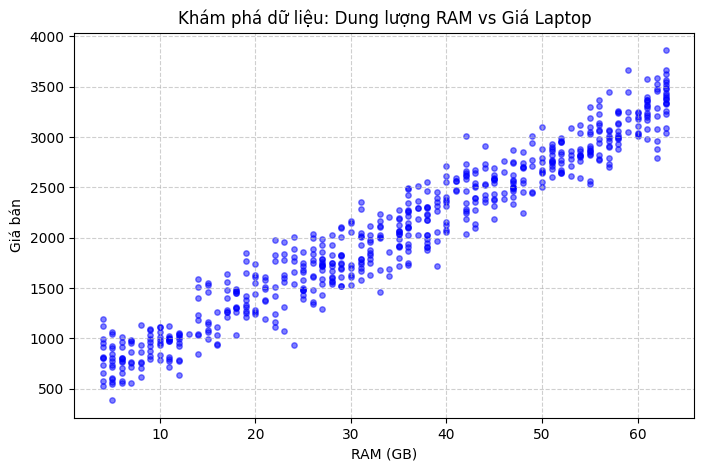


--- KẾT QUẢ NGHIỆM PHÂN TÍCH (NORMAL EQUATION) ---
Hệ số chặn (theta_0): 0.0000
Độ dốc (theta_1)  : 0.9695
Ghi chú: Bộ tham số này là mốc chuẩn để kiểm tra thuật toán Gradient Descent.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# TASK 1 & 2 (TV1): TẢI DỮ LIỆU THẬT VÀ LÀM SẠCH (DATA PREP)
# ==========================================
print("--- Đang nạp và xử lý dữ liệu Laptop từ Kaggle ---")

# 1. Đọc file CSV thật (đang nằm cùng thư mục)
df = pd.read_csv('laptop_price.csv', encoding='latin-1')

# 2. LÀM SẠCH DỮ LIỆU: Xóa chữ 'GB' trong cột Ram và ép về kiểu số nguyên (int)
df['Ram'] = df['Ram'].str.replace('GB', '').astype(int)

# 3. Trích xuất mảng X (RAM) và y (Giá bằng Euro)
X_raw = df['Ram'].values.reshape(-1, 1)
y_raw = df['Price_euros'].values.reshape(-1, 1)

print(f"-> Đã nạp thành công {len(df)} dòng dữ liệu thực tế!")

# --- Khám phá dữ liệu (EDA) ---
plt.figure(figsize=(10, 6))
plt.scatter(X_raw, y_raw, alpha=0.5, color='blue', s=15)
plt.title("Dung lượng RAM vs Giá Laptop (Euro) - Dữ liệu thực tế")
plt.xlabel("RAM (GB)")
plt.ylabel("Giá bán (Euro)")
plt.grid(True)
plt.show()

# ==========================================
# CHUẨN HÓA Z-SCORE VÀ TÍNH NORMAL EQUATION
# ==========================================
X_mean, X_std = np.mean(X_raw), np.std(X_raw)
y_mean, y_std = np.mean(y_raw), np.std(y_raw)

X_scaled = (X_raw - X_mean) / X_std
y_scaled = (y_raw - y_mean) / y_std

# Tính Normal Equation
X_b = np.c_[np.ones((len(X_scaled), 1)), X_scaled]
theta_analytical = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y_scaled)

print("\n--- KẾT QUẢ NGHIỆM PHÂN TÍCH (NORMAL EQUATION) ---")
print(f"Hệ số chặn (theta_0): {theta_analytical[0][0]:.4f}")
print(f"Độ dốc (theta_1)  : {theta_analytical[1][0]:.4f}")
print("Ghi chú: Bộ tham số này là mốc chuẩn để kiểm tra thuật toán Gradient Descent.")

In [2]:
# ==========================================
# TASK 3 & 4 (TV2): GRADIENT DESCENT VÀ COST FUNCTION
# ==========================================
print("\n--- BẮT ĐẦU HUẤN LUYỆN BẰNG GRADIENT DESCENT ---")

# 1. Hàm tính Cost Function (MSE)
def compute_cost(X, y, theta):
    m = len(y)
    predictions = X.dot(theta)
    cost = (1 / (2 * m)) * np.sum(np.square(predictions - y))
    return cost

# 2. Thuật toán Gradient Descent
def gradient_descent(X, y, theta, learning_rate, epochs):
    m = len(y)
    cost_history = np.zeros(epochs)
    theta_history = np.zeros((epochs, 2)) # Lưu vết theta để chuyển cho TV3 vẽ mặt cong 3D sau này

    for i in range(epochs):
        # TO-DO DÀNH CHO TV2: 
        # a. Tính giá trị dự đoán (predictions)
        # b. Tính đạo hàm (gradients) dựa trên sai số
        # c. Cập nhật tham số theta
        
        # --- Điền code thuật toán vào đây ---
        predictions = X.dot(theta)
        gradients = (1 / m) * X.T.dot(predictions - y)
        theta = theta - learning_rate * gradients
        # ------------------------------------
        
        # Lưu lịch sử cost và theta qua từng vòng lặp
        cost_history[i] = compute_cost(X, y, theta)
        theta_history[i, :] = theta.T
        
        if i % 100 == 0:
            print(f"Epoch {i}: Cost = {cost_history[i]:.4f}")
            
    return theta, cost_history, theta_history

# 3. Khởi tạo và thực thi (TV2 có thể tự do tinh chỉnh hyperparameters)
m = len(X_scaled)
X_b = np.c_[np.ones((m, 1)), X_scaled]
np.random.seed(42)
initial_theta = np.random.randn(2, 1)

alpha = 0.1     # Learning rate (Tốc độ học)
epochs = 1000   # Số vòng lặp

theta_gd, cost_history, theta_history = gradient_descent(X_b, y_scaled, initial_theta, alpha, epochs)

print("\n--- KẾT QUẢ GRADIENT DESCENT ---")
print(f"Hệ số chặn (theta_0): {theta_gd[0][0]:.4f}")
print(f"Độ dốc (theta_1)  : {theta_gd[1][0]:.4f}")
# Mục tiêu của TV2: Tinh chỉnh tham số sao cho kết quả này khớp với nghiệm chuẩn (Normal Equation) của TV1.


--- BẮT ĐẦU HUẤN LUYỆN BẰNG GRADIENT DESCENT ---
Epoch 0: Cost = 0.6269
Epoch 100: Cost = 0.0300
Epoch 200: Cost = 0.0300
Epoch 300: Cost = 0.0300
Epoch 400: Cost = 0.0300
Epoch 500: Cost = 0.0300
Epoch 600: Cost = 0.0300
Epoch 700: Cost = 0.0300
Epoch 800: Cost = 0.0300
Epoch 900: Cost = 0.0300

--- KẾT QUẢ GRADIENT DESCENT ---
Hệ số chặn (theta_0): 0.0000
Độ dốc (theta_1)  : 0.9695


In [3]:
# ==========================================
# TASK 5 (TV3): TRỰC QUAN HÓA 3D COST SURFACE VÀ CONTOUR PLOT
# ==========================================
# Đảm bảo đã chạy cell của TV2 trước khi chạy cell này để có hàm compute_cost và biến theta_history

print("\n--- CHUẨN BỊ VẼ BIỂU ĐỒ 3D COST SURFACE ---")

# Hàm tính toán ma trận Cost cho mặt cong 3D
def compute_cost_surface(X, y, theta0_range, theta1_range):
    J_vals = np.zeros((len(theta0_range), len(theta1_range)))
    for i, t0 in enumerate(theta0_range):
        for j, t1 in enumerate(theta1_range):
            t = np.array([[t0], [t1]])
            J_vals[i, j] = compute_cost(X, y, t)
    return J_vals

# TO-DO DÀNH CHO TV3:
# 1. Tạo lưới tham số (grid) cho theta0 và theta1 xung quanh giá trị tối ưu (có thể dùng np.linspace).
# 2. Gọi hàm compute_cost_surface() để tính ma trận độ cao J_vals.
# 3. Chuyển đổi lưới (meshgrid) và dùng matplotlib (ax.plot_surface) để vẽ mặt cong 3D.
# 4. Sử dụng plt.contour để vẽ bản đồ đường đồng mức (Contour plot) bên dưới mặt cong.
# 5. Vẽ đè mảng theta_history (do TV2 xuất ra) lên Contour plot để thấy đường đi hội tụ của thuật toán.

# --- Bắt đầu code của TV3 ở dưới đây ---


--- CHUẨN BỊ VẼ BIỂU ĐỒ 3D COST SURFACE ---
